In [ ]:
from typing import TypeAlias

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, random_split

TensorPair: TypeAlias = tuple[torch.Tensor, torch.Tensor]

import logging
import os
import warnings

import lightning as L
import numpy as np
from lightning.pytorch.callbacks import ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger

os.environ["LT_CLOUD"] = "0"

warnings.filterwarnings("ignore")

logging.getLogger("lightning").setLevel(logging.ERROR)
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
SEED = 42
BATCH_SIZE = 64
MANUAL_EPOCHS = 20
LIGHTNING_EPOCHS = 20
MANUAL_LR = 1e-2
LIGHTNING_LR = 1e-2
WEIGHT_DECAY = 1e-3

In [3]:
# Для выполнения последующих заданий воспользуйтесь предоставленным датасетом.
import pandas as pd

df = pd.read_parquet("../datasets/student_performance.parquet")

feature_names = [
    "attendance",
    "homework",
    "tests",
    "labs",
    "activity",
    "self_study",
    "assignments",
    "missed_classes",
]

target_names = [
    "grade_troechnik",
    "grade_horoshist",
    "grade_otlichnik",
]

X: pd.DataFrame = df[feature_names]
y_one_hot: pd.DataFrame = df[target_names]
y = pd.Series(
    y_one_hot.to_numpy().argmax(axis=1),
    index=y_one_hot.index,
)

print("X:", X.shape)  # (1500, 8)
print("y_one_hot:", y_one_hot.shape)  # (1500, 3)
print("Распределение классов:", y_one_hot.sum().to_dict())

df.head()

X: (1500, 8)
y_one_hot: (1500, 3)
Распределение классов: {'grade_troechnik': 500, 'grade_horoshist': 500, 'grade_otlichnik': 500}


,attendance,homework,tests,labs,activity,self_study,assignments,missed_classes,grade_troechnik,grade_horoshist,grade_otlichnik
0,84.358971,84.858231,72.557571,75.903267,6.417617,6.885142,77.967903,10.898900,0,1,0
1,98.150200,99.825562,92.924957,90.735123,9.094598,12.813385,96.035950,1.231400,0,0,1
2,68.599190,56.878910,52.272404,60.921814,3.540313,2.756527,51.648708,19.054539,1,0,0
3,82.031723,83.181419,81.585976,80.341942,6.781160,6.840117,79.168808,9.980979,0,1,0
4,65.119080,58.842937,44.188740,47.104664,3.595831,2.994307,55.680706,17.306808,1,0,0


In [4]:
# Задание 3: реализуйте собственный nn.Module для классификации трёх классов.
class StudentClassifier(nn.Module):
    # Конструктор должен зарегистрировать слои через атрибуты self, чтобы PyTorch видел их параметры.
    def __init__(
        self,
        in_features: int = 8,
        hidden_features: tuple[int, ...] = (16, 16),
        num_classes: int = 3,
    ) -> None:
        super().__init__()

        layers = []

        for features in hidden_features:
            layers.append(nn.Linear(in_features, features))
            layers.append(nn.ReLU())

            in_features = features

        layers.append(nn.Linear(in_features, num_classes))

        self.sequential = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.sequential(x)


# Ваше задание: после реализации проверьте формы входа и выхода и число параметров.

model = StudentClassifier()
print(model)

example_batch = torch.randn(8, 8)

logits = model(example_batch)
print("Вход:", tuple(example_batch.shape))
print("Выход:", tuple(logits.shape))

print("Всего параметров:", sum(parameter.numel() for parameter in model.parameters()))

StudentClassifier(
  (sequential): Sequential(
    (0): Linear(in_features=8, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=3, bias=True)
  )
)
Вход: (8, 8)
Выход: (8, 3)
Всего параметров: 467


In [5]:
# Задание 4: создайте Dataset и DataLoader для собственных признаков и меток.
class StudentDataset(Dataset[TensorPair]):
    def __init__(self, X: pd.DataFrame, y: pd.DataFrame) -> None:
        if X.ndim != 2:
            raise ValueError(
                "features должен иметь форму (число объектов, число признаков)"
            )

        if y.ndim != 1:
            raise ValueError("labels должен быть одномерным тензором")

        if len(X) != len(y):
            raise ValueError("Число объектов должно совпадать с числом меток")

        self.features = torch.from_numpy(X.to_numpy(dtype=np.float32))
        self.labels = torch.from_numpy(y.to_numpy(dtype=np.int64))

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, idx: int) -> TensorPair:
        return self.features[idx], self.labels[idx]


# Ваше задание: создайте экземпляр Dataset, проверьте первый объект.
# Разбейте на train/validation/test в соотношении 70%/15%/15%.

dataset = StudentDataset(X, y)
print("Число объектов:", len(dataset))
print("Форма признаков всего датасета:", tuple(dataset.features.shape))
print("Форма меток всего датасета:", tuple(dataset.labels.shape))
print("Один пример:", dataset[0])

train_size = int(0.70 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

split_generator = torch.Generator().manual_seed(SEED)
train_ds, val_ds, test_ds = random_split(
    dataset, [train_size, val_size, test_size], generator=split_generator
)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train: {len(train_ds)} объектов")
print(f"Validation: {len(val_ds)} объектов")
print(f"Test: {len(test_ds)} объектов")

xb, yb = next(iter(train_loader))
print("Форма батча признаков:", tuple(xb.shape))
print("Форма батча меток:", tuple(yb.shape), "dtype:", yb.dtype)

Число объектов: 1500
Форма признаков всего датасета: (1500, 8)
Форма меток всего датасета: (1500,)
Один пример: (tensor([84.3590, 84.8582, 72.5576, 75.9033,  6.4176,  6.8851, 77.9679, 10.8989]), tensor(1))
Train: 1050 объектов
Validation: 225 объектов
Test: 225 объектов
Форма батча признаков: (64, 8)
Форма батча меток: (64,) dtype: torch.int64


In [6]:
# Задание 5: заполните один шаг ручного обучения, используя собственную модель и один батч.
# После реализации StudentClassifier раскомментируйте заготовку ниже.
# Следующие строки задают объекты, с которыми нужно выполнить полный ручной шаг оптимизации.
student_model = StudentClassifier().to(device)
student_optimizer = torch.optim.AdamW(
    student_model.parameters(), lr=MANUAL_LR, weight_decay=WEIGHT_DECAY
)
student_criterion = nn.CrossEntropyLoss()

# Ваше задание: перенесите батч на device, вызовите zero_grad, forward, loss, backward и optimizer.step.

xb, yb = next(iter(train_loader))
xb, yb = xb.to(device), yb.to(device)

student_model.train()

student_model.zero_grad(set_to_none=True)

logits = student_model(xb)

loss = student_criterion(logits, yb)

loss.backward()

student_optimizer.step()

In [7]:
# Задание 6: обучите свою модель через Lightning и сохраните лучший чекпойнт.
# Используйте LitClassifier как ориентир для реализации собственного LightningModule.
# После реализации StudentLitClassifier раскомментируйте заготовку ниже.


class StudentLitClassifier(L.LightningModule):
    def __init__(self, lr: float = 1e-2, weight_decay: float = 1e-3) -> None:
        super().__init__()

        self.save_hyperparameters()

        self.model = StudentClassifier()

        self.criterion = nn.CrossEntropyLoss()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.model(x)

    def training_step(self, batch: TensorPair, batch_idx: int) -> torch.Tensor:
        features_batch, labels_batch = batch

        logits = self(features_batch)

        loss = self.criterion(logits, labels_batch)

        accuracy = (logits.argmax(dim=1) == labels_batch).float().mean()

        self.log(
            "train_loss",
            loss,
            on_step=False,
            on_epoch=True,
            prog_bar=True,
            batch_size=labels_batch.size(0),
        )

        self.log(
            "train_accuracy",
            accuracy,
            on_step=False,
            on_epoch=True,
            batch_size=labels_batch.size(0),
        )

        return loss

    def validation_step(self, batch: TensorPair, batch_idx: int) -> None:
        features_batch, labels_batch = batch

        logits = self(features_batch)

        loss = self.criterion(logits, labels_batch)

        accuracy = (logits.argmax(dim=1) == labels_batch).float().mean()

        self.log(
            "val_loss",
            loss,
            on_step=False,
            on_epoch=True,
            prog_bar=True,
            batch_size=labels_batch.size(0),
        )

        self.log(
            "val_accuracy",
            accuracy,
            on_step=False,
            on_epoch=True,
            batch_size=labels_batch.size(0),
        )

    def test_step(self, batch: TensorPair, batch_idx: int) -> None:
        features_batch, labels_batch = batch

        logits = self(features_batch)

        loss = self.criterion(logits, labels_batch)

        accuracy = (logits.argmax(dim=1) == labels_batch).float().mean()

        self.log(
            "test_loss",
            loss,
            on_step=False,
            on_epoch=True,
            batch_size=labels_batch.size(0),
        )

        self.log(
            "test_accuracy",
            accuracy,
            on_step=False,
            on_epoch=True,
            batch_size=labels_batch.size(0),
        )

    def configure_optimizers(self) -> torch.optim.Optimizer:
        return torch.optim.AdamW(
            self.parameters(),
            lr=float(self.hparams.lr),
            weight_decay=float(self.hparams.weight_decay),
        )


student_lightning_model = StudentLitClassifier(
    lr=LIGHTNING_LR, weight_decay=WEIGHT_DECAY
)

# Callback должен сохранять веса модели с минимальным val_loss.
student_checkpoint = ModelCheckpoint(
    dirpath="checkpoints",
    filename="student-classifier-{epoch:02d}-{val_loss:.4f}",
    monitor="val_loss",
    mode="min",
    save_top_k=1,
)

csv_logger = CSVLogger(save_dir="logs", name="student-classifier")

# Создаём Trainer с небольшим числом эпох и callback сохранения; затем добавьте вызов fit().
student_trainer = L.Trainer(
    max_epochs=LIGHTNING_EPOCHS,
    accelerator="auto",
    devices=1,
    logger=csv_logger,
    callbacks=[student_checkpoint],
    enable_progress_bar=True,
)

# Ваше задание: запустите trainer.fit(...) со своими train и validation DataLoader.

student_trainer.fit(
    student_lightning_model, train_dataloaders=train_loader, val_dataloaders=val_loader
)

Epoch 19: 100%|██████████| 17/17 [00:00<00:00, 135.08it/s, v_num=1, val_loss=0.0135, train_loss=0.00266] 


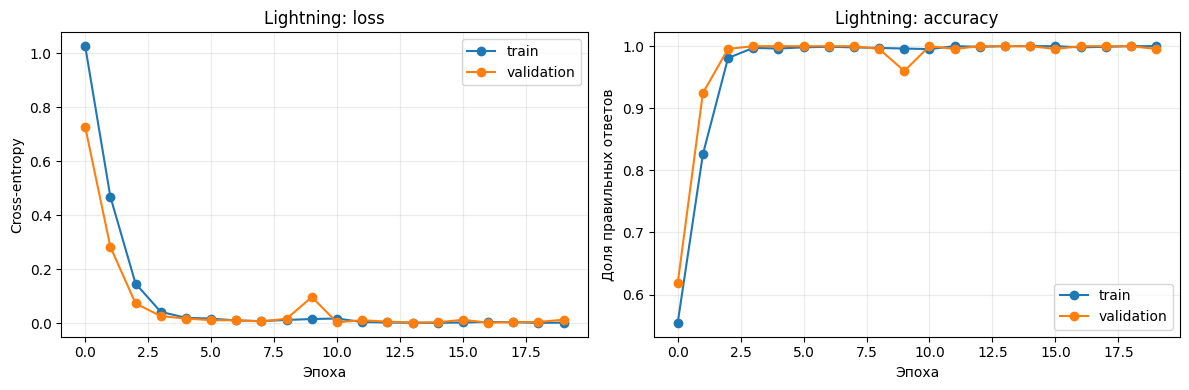

Testing DataLoader 0: 100%|██████████| 4/4 [00:00<00:00, 238.56it/s]
Тест Lightning: [{'test_loss': 0.0015087771462276578, 'test_accuracy': 1.0}]


In [8]:
# Задание 7: визуализируйте историю обучения и сохраните/восстановите состояние своей модели.
# Используйте историю метрик и сохранённые веса: после загрузки проверьте, что качество не изменилось из-за ошибки восстановления.
# Ваше задание: постройте графики train/validation loss и accuracy, сохраните state_dict,
# восстановите новый экземпляр архитектуры и оцените его на test.

from pathlib import Path
from matplotlib import pyplot as plt


metrics_path = Path(csv_logger.log_dir) / "metrics.csv"

metrics_df = pd.read_csv(metrics_path)

epoch_metrics = metrics_df.groupby("epoch", as_index=False).last()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

if "train_loss" in epoch_metrics:
    axes[0].plot(
        epoch_metrics["epoch"],
        epoch_metrics["train_loss"],
        marker="o",
        label="train",
    )

if "val_loss" in epoch_metrics:
    axes[0].plot(
        epoch_metrics["epoch"],
        epoch_metrics["val_loss"],
        marker="o",
        label="validation",
    )

axes[0].set_title("Lightning: loss")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Cross-entropy")
axes[0].legend()
axes[0].grid(alpha=0.25)

if "train_accuracy" in epoch_metrics:
    axes[1].plot(
        epoch_metrics["epoch"],
        epoch_metrics["train_accuracy"],
        marker="o",
        label="train",
    )

if "val_accuracy" in epoch_metrics:
    axes[1].plot(
        epoch_metrics["epoch"],
        epoch_metrics["val_accuracy"],
        marker="o",
        label="validation",
    )

axes[1].set_title("Lightning: accuracy")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Доля правильных ответов")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

restored_lightning_model = StudentLitClassifier.load_from_checkpoint(
    student_checkpoint.best_model_path, map_location="cpu"
)

test_results = student_trainer.test(
    restored_lightning_model, dataloaders=test_loader, verbose=False
)

print("Тест Lightning:", test_results)